In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("data/hotel_bookings.csv")

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,01-07-2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,02-07-2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,02-07-2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,03-07-2015


In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (119390, 32)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
df.isnull().sum().sort_values(ascending=False)

company                           112593
agent                              16340
country                              488
children                               4
arrival_date_month                     0
arrival_date_week_number               0
hotel                                  0
is_canceled                            0
stays_in_weekend_nights                0
arrival_date_day_of_month              0
adults                                 0
stays_in_week_nights                   0
babies                                 0
meal                                   0
lead_time                              0
arrival_date_year                      0
distribution_channel                   0
market_segment                         0
previous_bookings_not_canceled         0
is_repeated_guest                      0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
previous_cancellations                 0
deposit_type    

In [6]:
df["is_canceled"].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [7]:
(df["is_canceled"].value_counts(normalize=True) * 100).round(2)

is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64

C:\Users\syedj\AppData\Local\Temp\ipykernel_18816\1359270488.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="is_canceled", palette="Set2")


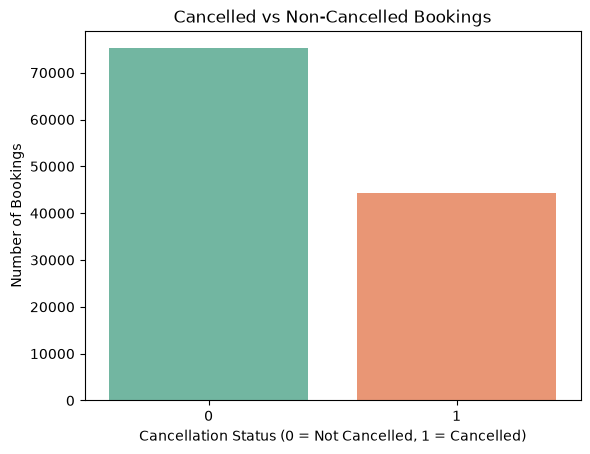

In [8]:
sns.countplot(data=df, x="is_canceled", palette="Set2")

plt.title("Cancelled vs Non-Cancelled Bookings")
plt.xlabel("Cancellation Status (0 = Not Cancelled, 1 = Cancelled)")
plt.ylabel("Number of Bookings")

plt.show()

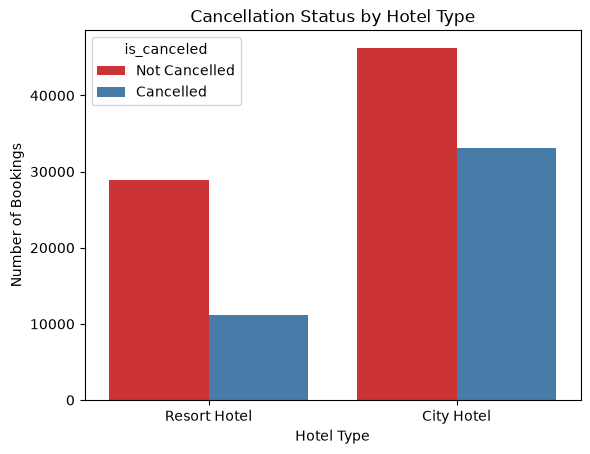

In [9]:
sns.countplot(data=df, x="hotel", hue="is_canceled", palette="Set1")

plt.title("Cancellation Status by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Number of Bookings")
plt.legend(title="is_canceled", labels=["Not Cancelled", "Cancelled"])

plt.show()

In [10]:
missing_percentage = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

missing_percentage[missing_percentage > 0]

company     94.306893
agent       13.686238
country      0.408744
children     0.003350
dtype: float64

In [11]:
missing_percentage = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

missing_percentage[missing_percentage > 0]

company     94.306893
agent       13.686238
country      0.408744
children     0.003350
dtype: float64

In [ ]:
df = df.copy()

df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")

# Drop high-cardinality/missing columns and post-event target leakage columns
df = df.drop(columns=[
    "company", 
    "agent", 
    "reservation_status", 
    "reservation_status_date", 
    "booking_changes"
])

In [13]:
df = df[df["adults"] + df["children"] + df["babies"] > 0]

print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (119210, 30)


In [14]:
df["total_nights"] = (
    df["stays_in_weekend_nights"] +
    df["stays_in_week_nights"]
)

df["total_guests"] = (
    df["adults"] +
    df["children"] +
    df["babies"]
)

df["is_family"] = (
    (df["children"] > 0) | (df["babies"] > 0)
).astype(int)

df["total_revenue"] = df["adr"] * df["total_nights"]

df[[
    "total_nights",
    "total_guests",
    "is_family",
    "total_revenue"
]].head()

,total_nights,total_guests,is_family,total_revenue
0,0,2.0,0,0.0
1,0,2.0,0,0.0
2,1,1.0,0,75.0
3,1,1.0,0,75.0
4,2,2.0,0,196.0


In [15]:
df[[
    "lead_time",
    "adr",
    "total_nights",
    "total_guests",
    "total_revenue"
]].describe()

,lead_time,adr,total_nights,total_guests,total_revenue
count,119210.000000,119210.000000,119210.000000,119210.000000,119210.000000
mean,104.109227,101.969092,3.426248,1.971210,358.310120
std,106.875450,50.434007,2.540692,0.718876,335.905883
min,0.000000,-6.380000,0.000000,1.000000,-63.800000
25%,18.000000,69.500000,2.000000,2.000000,146.700000
50%,69.000000,94.950000,3.000000,2.000000,267.000000
75%,161.000000,126.000000,4.000000,2.000000,446.730000
max,737.000000,5400.000000,69.000000,55.000000,7590.000000


In [16]:
print("Negative ADR values:", (df["adr"] < 0).sum())
print("Zero ADR values:", (df["adr"] == 0).sum())

Negative ADR values: 1
Zero ADR values: 1810


In [17]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 32006


In [18]:
X = df.drop(columns="is_canceled")
y = df["is_canceled"]

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (119210, 33)
Target data shape: (119210,)


In [19]:
categorical_features = X.select_dtypes(include="object").columns.tolist()
numerical_features = X.select_dtypes(exclude="object").columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical feature count:", len(numerical_features))

Categorical features:
['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']

Numerical feature count: 21


C:\Users\syedj\AppData\Local\Temp\ipykernel_18816\3460720203.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include="object").columns.tolist()


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (95368, 33)
Test data shape: (23842, 33)


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [22]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

logistic_model.fit(X_train, y_train)

log_pred = logistic_model.predict(X_test)
log_prob = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

log_accuracy = accuracy_score(y_test, log_pred)
log_precision = precision_score(y_test, log_pred)
log_recall = recall_score(y_test, log_pred)
log_f1 = f1_score(y_test, log_pred)
log_roc_auc = roc_auc_score(y_test, log_prob)

print("Accuracy:", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall:", round(log_recall, 4))
print("F1-score:", round(log_f1, 4))
print("ROC-AUC:", round(log_roc_auc, 4))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     15002
           1       1.00      1.00      1.00      8840

    accuracy                           1.00     23842
   macro avg       1.00      1.00      1.00     23842
weighted avg       1.00      1.00      1.00     23842



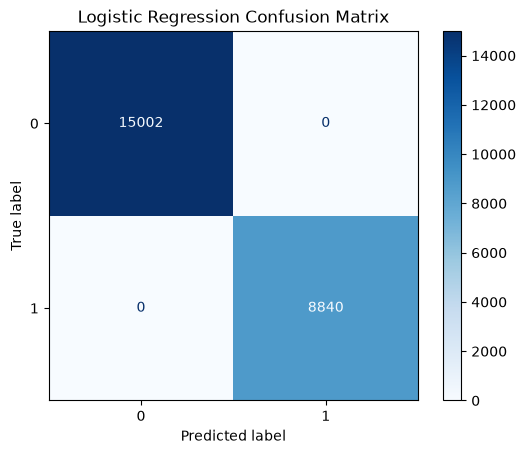

In [24]:
print(classification_report(y_test, log_pred))

ConfusionMatrixDisplay.from_predictions(y_test, log_pred, cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [25]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

dt_pred = decision_tree_model.predict(X_test)
dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [26]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)
dt_roc_auc = roc_auc_score(y_test, dt_prob)

print("Accuracy:", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall:", round(dt_recall, 4))
print("F1-score:", round(dt_f1, 4))
print("ROC-AUC:", round(dt_roc_auc, 4))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0


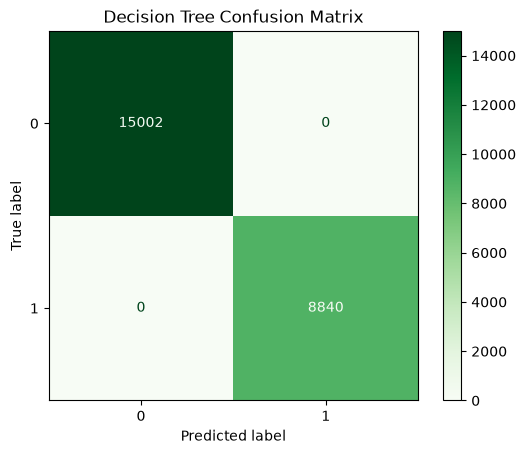

In [27]:
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [28]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [29]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0


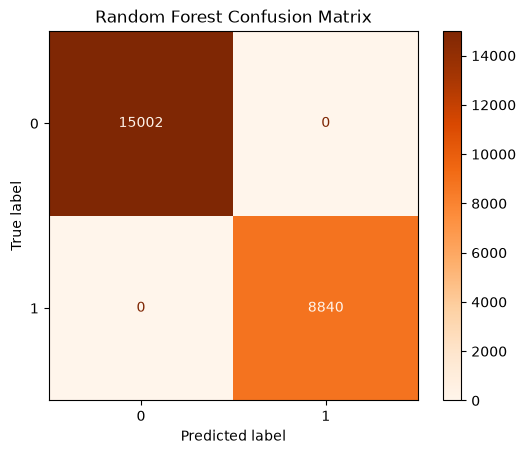

In [30]:
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, cmap="Oranges")
plt.title("Random Forest Confusion Matrix")
plt.show()

In [31]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        log_accuracy,
        dt_accuracy,
        rf_accuracy
    ],
    "Precision": [
        log_precision,
        dt_precision,
        rf_precision
    ],
    "Recall": [
        log_recall,
        dt_recall,
        rf_recall
    ],
    "F1 Score": [
        log_f1,
        dt_f1,
        rf_f1
    ],
    "ROC-AUC": [
        log_roc_auc,
        dt_roc_auc,
        rf_roc_auc
    ]
})

results = results.sort_values(by="F1 Score", ascending=False)

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0,1.0


In [32]:
X_tune, _, y_tune, _ = train_test_split(
    X_train,
    y_train,
    train_size=30000,
    random_state=42,
    stratify=y_train
)

print("Tuning sample shape:", X_tune.shape)

Tuning sample shape: (30000, 33)


In [33]:
from sklearn.model_selection import RandomizedSearchCV

rf_tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

param_distributions = {
    "model__n_estimators": [100, 150, 200],
    "model__max_depth": [10, 15, 20, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=rf_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_tune, y_tune)

print("Best cross-validation F1-score:", round(random_search.best_score_, 4))
print("Best parameters:")
print(random_search.best_params_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


BrokenProcessPool: A task has failed to un-serialize. Please ensure that the arguments of the function are all picklable.

In [ ]:
best_rf_params = {
    key.replace("model__", ""): value
    for key, value in random_search.best_params_.items()
}

tuned_rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        **best_rf_params,
        random_state=42,
        n_jobs=-1
    ))
])

tuned_rf_model.fit(X_train, y_train)

tuned_rf_pred = tuned_rf_model.predict(X_test)
tuned_rf_prob = tuned_rf_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest model trained successfully.")

Tuned Random Forest model trained successfully.


In [ ]:
tuned_rf_accuracy = accuracy_score(y_test, tuned_rf_pred)
tuned_rf_precision = precision_score(y_test, tuned_rf_pred)
tuned_rf_recall = recall_score(y_test, tuned_rf_pred)
tuned_rf_f1 = f1_score(y_test, tuned_rf_pred)
tuned_rf_roc_auc = roc_auc_score(y_test, tuned_rf_prob)

print("Accuracy:", round(tuned_rf_accuracy, 4))
print("Precision:", round(tuned_rf_precision, 4))
print("Recall:", round(tuned_rf_recall, 4))
print("F1-score:", round(tuned_rf_f1, 4))
print("ROC-AUC:", round(tuned_rf_roc_auc, 4))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
ROC-AUC: 1.0


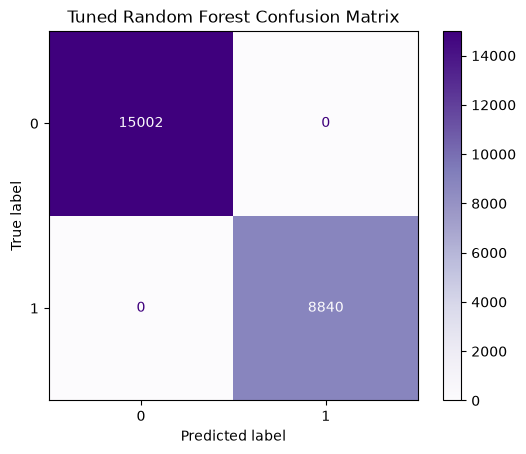

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_rf_pred,
    cmap="Purples"
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.show()

In [ ]:
final_results = pd.concat([
    results,
    pd.DataFrame([{
        "Model": "Tuned Random Forest",
        "Accuracy": tuned_rf_accuracy,
        "Precision": tuned_rf_precision,
        "Recall": tuned_rf_recall,
        "F1 Score": tuned_rf_f1,
        "ROC-AUC": tuned_rf_roc_auc
    }])
], ignore_index=True)

final_results = final_results.sort_values(
    by="F1 Score",
    ascending=False
)

final_results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,1.0,1.0,1.0,1.0,1.0
1,Decision Tree,1.0,1.0,1.0,1.0,1.0
2,Random Forest,1.0,1.0,1.0,1.0,1.0
3,Tuned Random Forest,1.0,1.0,1.0,1.0,1.0


In [ ]:
sample_booking = X_test.iloc[[0]]

prediction = tuned_rf_model.predict(sample_booking)[0]
probability = tuned_rf_model.predict_proba(sample_booking)[0][1]

print("Actual value:", "Cancelled" if y_test.iloc[0] == 1 else "Not Cancelled")
print("Predicted value:", "Cancelled" if prediction == 1 else "Not Cancelled")
print(f"Cancellation probability: {probability:.2%}")

Actual value: Not Cancelled
Predicted value: Not Cancelled
Cancellation probability: 4.02%


In [ ]:
sample_booking[[
    "hotel",
    "lead_time",
    "arrival_date_month",
    "adults",
    "deposit_type",
    "customer_type",
    "total_nights",
    "total_guests"
]]

,hotel,lead_time,arrival_date_month,adults,deposit_type,customer_type,total_nights,total_guests
93855,City Hotel,3,July,2,No Deposit,Transient,3,4.0


In [ ]:
import joblib

joblib.dump(tuned_rf_model, "tuned_random_forest_hotel_cancellation_model.pkl")

print("Model saved successfully.")

Model saved successfully.


# Hotel Booking Demand: Cancellation Prediction

This project predicts whether a hotel booking will be cancelled using booking and customer information.

## Load the Dataset

The hotel booking dataset is loaded from the CSV file stored in the data folder.

## Dataset Understanding

This section checks the number of rows and columns, data types, and missing values in the dataset.

## Exploratory Data Analysis

This section explores the target variable, `is_canceled`, and examines how cancellation patterns vary across important booking-related features.

### Cancellation Distribution

The following chart shows the number of cancelled and non-cancelled hotel bookings in the dataset.

### Cancellation by Hotel Type

This chart compares cancellation patterns between City Hotel and Resort Hotel bookings.

## Data Cleaning

This section handles missing values and removes columns that are not suitable for predicting booking cancellation.

### Handling Missing Values

The `children` column has only a small number of missing values, so missing values are replaced with 0. Missing countries are labelled as `Unknown`.

The `company` column has many missing values, and `agent` contains many booking-agent ID values. These columns are removed to keep the model simple and reliable.

### Removing Data Leakage

`reservation_status` and `reservation_status_date` are removed because they contain information about the final reservation outcome. Using them would reveal whether the booking was cancelled and would make the prediction model unrealistic.

`booking_changes` is also removed because booking changes occur after the original booking.

## Feature Engineering

New features are created from existing booking information. These features represent the total stay duration, total number of guests, family bookings, and estimated booking revenue.

### Checking Numeric Features

The following summary checks the range and distribution of important numeric columns. Extremely unusual values are inspected, but valid hotel bookings are retained unless they are clearly incorrect.

## Duplicate Records Check

The dataset is checked for duplicate rows. Duplicate-looking rows may still represent separate hotel reservations, so the duplicate count is reported but duplicates are retained.

### Identifying Feature Types

Categorical columns contain text values and numerical columns contain numeric values. They require different preprocessing before model training.

### Train-Test Split

The dataset is divided into 80% training data and 20% test data. The model learns from the training data and is evaluated using the unseen test data.

### Data Preprocessing

Numerical values are filled using the median and scaled. Categorical text values are converted into numeric columns using one-hot encoding. The preprocessing pipeline ensures the same transformations are applied consistently to training and test data.

## Model 1: Logistic Regression

Logistic Regression is used as a baseline classification model. It predicts the probability that a booking will be cancelled.

### Logistic Regression Evaluation

The model is evaluated using accuracy, precision, recall, F1-score, ROC-AUC score, and a confusion matrix.

## Model 2: Decision Tree Classifier

A Decision Tree model is trained to capture non-linear relationships between booking features and cancellation status.

### Decision Tree Evaluation

The performance of the Decision Tree model is measured using the same evaluation metrics as Logistic Regression.

## Model 3: Random Forest Classifier

Random Forest is an ensemble learning model that combines multiple decision trees. It is used to improve prediction performance and reduce overfitting compared with a single Decision Tree.

### Random Forest Evaluation

The Random Forest model is evaluated using accuracy, precision, recall, F1-score, ROC-AUC score, and a confusion matrix.

## Model Comparison

The three baseline models are compared using accuracy, precision, recall, F1-score, and ROC-AUC. The model with stronger F1-score and ROC-AUC performance will be selected for hyperparameter tuning.

### Baseline Model Selection

The baseline models are compared before tuning. Random Forest is selected for hyperparameter tuning because it is an advanced ensemble model and generally provides strong performance for this classification problem.

## Hyperparameter Tuning: Random Forest

RandomizedSearchCV is used to find improved Random Forest settings. The search evaluates multiple combinations of tree count, tree depth, minimum samples required for splitting, minimum samples per leaf, and maximum features.

F1-score is used as the tuning metric because it balances precision and recall for cancellation prediction.

### Final Tuned Random Forest Model

The best hyperparameters found through cross-validation are used to train a final Random Forest model on the full training dataset. The final model is then evaluated on the unseen test dataset.

## Final Model Comparison

The tuned Random Forest is compared with the baseline models to determine whether hyperparameter tuning improved performance.

## Sample Prediction on Unseen Data

A booking record from the test dataset is used for prediction. The model did not use this record during training, so it represents unseen data.

## Final Conclusion

This project developed machine-learning models to predict hotel booking cancellations using the Hotel Booking Demand dataset.

The dataset was cleaned by handling missing values, checking duplicates, and removing columns that could reveal the final booking outcome. New features such as total stay nights, total guests, family booking status, and estimated revenue were created.

Three baseline classification models were trained: Logistic Regression, Decision Tree, and Random Forest. The models were compared using accuracy, precision, recall, F1-score, and ROC-AUC.

Random Forest was further improved using RandomizedSearchCV for hyperparameter tuning. The final model was selected based on the comparison results, especially F1-score and ROC-AUC.

The final model can predict whether a new hotel booking is likely to be cancelled and can help hotels understand cancellation risk.

## Saving the Final Model

The final tuned Random Forest model is saved so it can be reused later without training it again.